# IDX Exchange DS Internship - Week Five -  Additional Models

* Try Decision Tree and Random Forest regressors.
* Compare their test R² against baseline.
* Document model behavior (strengths/weaknesses)

In [46]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler

from sklearn import base
from sklearn.model_selection import KFold
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import TargetEncoder

import matplotlib.pyplot as plt

## Import Data

In [47]:
dataset = pd.read_csv("week_3_cleaned_op2.csv")

### Encode Variables with a Train/Test Split

In [66]:
train_set = dataset[dataset["TestSetTrue"] == 0]
test_set = dataset[dataset["TestSetTrue"] == 1]

to_encode_train = train_set[["ListOfficeName", "CountyOrParish", "HighSchoolDistrict", "imputed_city", "PostalCode", "imputed_year_built"]]
to_encode_test = test_set[["ListOfficeName", "CountyOrParish", "HighSchoolDistrict", "imputed_city", "PostalCode", "imputed_year_built"]]

y_train = train_set["ClosePriceLog"]
y_test = test_set["ClosePriceLog"]

In [67]:
encoder = TargetEncoder(smooth="auto", cv=5, random_state=42)

x_train_encoded = encoder.fit_transform(to_encode_train, y_train)
x_test_encoded = encoder.transform(to_encode_test)

x_train_encoded_df = pd.DataFrame(x_train_encoded, columns=to_encode_train.columns)
x_test_encoded_df = pd.DataFrame(x_test_encoded, columns=to_encode_train.columns)

In [68]:
x_train = train_set[["ViewYN", "PoolPrivateYN", "AttachedGarageYN", "FireplaceYN", "NewConstructionYN",
                    "LivingAreaLog", "LotSizeSquareFeetLog", "AssociationFeeLog",
                    "ParkingTotalWinz", 'BathroomsTotalIntegerWinz', 'BedroomsTotalWinz', 'MainLevelBedroomsWinz','GarageSpacesWinz', 'ImputedStoriesWinz',
                    'Bamboo', 'Brick', 'Carpet', 'Concrete', 'Laminate', 'Stone', 'Tile', 'Unknown', 'Vinyl', 'Wood',
                    'StateOrProvince_AZ','StateOrProvince_CA', 'StateOrProvince_CO', 'StateOrProvince_FL', 'StateOrProvince_GA',
                    'StateOrProvince_ME', 'StateOrProvince_NV','StateOrProvince_NY', 'StateOrProvince_OS', 'StateOrProvince_TN', 'StateOrProvince_TX']]
x_train_enc = x_train.join(x_train_encoded_df)

x_test = test_set[["ViewYN", "PoolPrivateYN", "AttachedGarageYN", "FireplaceYN", "NewConstructionYN",
                    "LivingAreaLog", "LotSizeSquareFeetLog", "AssociationFeeLog",
                    "ParkingTotalWinz", 'BathroomsTotalIntegerWinz', 'BedroomsTotalWinz', 'MainLevelBedroomsWinz','GarageSpacesWinz', 'ImputedStoriesWinz',
                    'Bamboo', 'Brick', 'Carpet', 'Concrete', 'Laminate', 'Stone', 'Tile', 'Unknown', 'Vinyl', 'Wood',
                    'StateOrProvince_AZ','StateOrProvince_CA', 'StateOrProvince_CO', 'StateOrProvince_FL', 'StateOrProvince_GA',
                    'StateOrProvince_ME', 'StateOrProvince_NV','StateOrProvince_NY', 'StateOrProvince_OS', 'StateOrProvince_TN', 'StateOrProvince_TX']].reset_index(drop=True)
x_test_enc = x_test.join(x_test_encoded_df)

## Decision Tree

### Model One: Baseline Dataset

In [69]:
depths = range(1, 20)
train_r2_scores = []
test_r2_scores = []

for depth in depths:
    model = DecisionTreeRegressor(max_depth=depth, random_state=42)
    model.fit(x_train_enc, y_train)

    train_r2 = model.score(x_train_enc, y_train)
    test_r2 = model.score(x_test_enc, y_test)

    train_r2_scores.append(train_r2)
    test_r2_scores.append(test_r2)

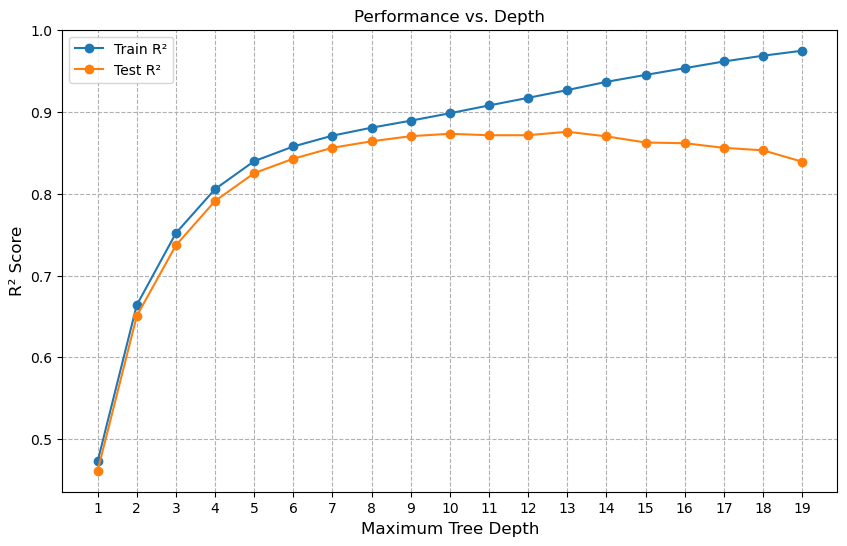

In [70]:
plt.figure(figsize=(10, 6))
plt.plot(depths, train_r2_scores, marker="o", label="Train R²")
plt.plot(depths, test_r2_scores, marker="o", label="Test R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

In [71]:
model = DecisionTreeRegressor(max_depth=10, random_state=42)
model.fit(x_train_enc, y_train)

y_pred = model.predict(x_test_enc)

score = r2_score(y_test, y_pred)
score

0.8731425495442937

On this same data, the baseline linear regression model got 0.888, which is just slightly higher than this Decision Tree baseline.

### Model Two: No Scaling on Input Features

In [80]:
# Decision Trees often don't require any sort of scaling
# Test how a Decisionn Tree performs when the log is removed from LivingArea, LotSizeSquareFeet, and AssocitationFee
# Note that you don't remove the log for ClosePrice, otherwise the target variable is extremely skewed

no_log_train = train_set[["LivingArea", "LotSizeSquareFeet", "AssociationFee"]]
no_log_test = test_set[["LivingArea", "LotSizeSquareFeet", "AssociationFee"]]

x_train_no_scale = x_train_enc.join(no_log_train).drop(columns = ["LivingAreaLog", "LotSizeSquareFeetLog", "AssociationFeeLog"])
x_test_no_scale = x_test_enc.join(no_log_test).drop(columns = ["LivingAreaLog", "LotSizeSquareFeetLog", "AssociationFeeLog"])

y_train_no_scale = train_set["ClosePriceLog"]
y_test_no_scale = test_set["ClosePriceLog"]

In [81]:
depths = range(1, 20)
train_r2_scores = []
test_r2_scores = []

for depth in depths:
    model = DecisionTreeRegressor(max_depth=depth, random_state=42)
    model.fit(x_train_no_scale, y_train_no_scale)

    train_r2 = model.score(x_train_no_scale, y_train_no_scale)
    test_r2 = model.score(x_test_no_scale, y_test_no_scale)

    train_r2_scores.append(train_r2)
    test_r2_scores.append(test_r2)

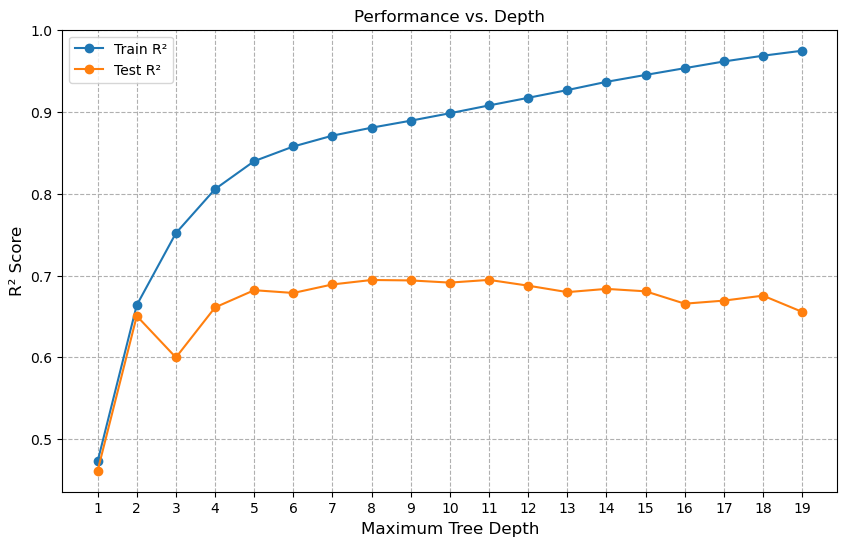

In [82]:
plt.figure(figsize=(10, 6))
plt.plot(depths, train_r2_scores, marker="o", label="Train R²")
plt.plot(depths, test_r2_scores, marker="o", label="Test R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

In [83]:
model = DecisionTreeRegressor(max_depth=9, random_state=42)
model.fit(x_train_no_scale, y_train_no_scale)

y_pred = model.predict(x_test_no_scale)

score = r2_score(y_test_no_scale, y_pred)
score

0.694014938075306

There is a significant drop in model performance when the log is removed from input features. This is likely because the outliers remaning in the dataset are skewing the tree's rule choices.

### Model Three: No Scaling on Input Features + Outlier Removal on all Features

In [14]:
# Test to see if removing outliers (via winsorization) fixes the problem that arose from removing the log

to_remove_outliers_train = train_set[["LivingArea", "LotSizeSquareFeet", "AssociationFee"]]
to_remove_outliers_test = test_set[["LivingArea", "LotSizeSquareFeet", "AssociationFee"]]

# Train dataset
upper_bound = to_remove_outliers_train["LivingArea"].quantile(0.95)
to_remove_outliers_train["LivingArea"] = to_remove_outliers_train["LivingArea"].clip(lower=0, upper=upper_bound)

upper_bound = to_remove_outliers_train["LotSizeSquareFeet"].quantile(0.95)
to_remove_outliers_train["LotSizeSquareFeet"] = to_remove_outliers_train["LotSizeSquareFeet"].clip(lower=0, upper=upper_bound)

upper_bound = to_remove_outliers_train["AssociationFee"].quantile(0.95)
to_remove_outliers_train["AssociationFee"] = to_remove_outliers_train["AssociationFee"].clip(lower=0, upper=upper_bound)

# Test dataset
upper_bound = to_remove_outliers_test["LivingArea"].quantile(0.95)
to_remove_outliers_test["LivingArea"] = to_remove_outliers_test["LivingArea"].clip(lower=0, upper=upper_bound)

upper_bound = to_remove_outliers_test["LotSizeSquareFeet"].quantile(0.95)
to_remove_outliers_test["LotSizeSquareFeet"] = to_remove_outliers_test["LotSizeSquareFeet"].clip(lower=0, upper=upper_bound)

upper_bound = to_remove_outliers_test["AssociationFee"].quantile(0.95)
to_remove_outliers_test["AssociationFee"] = to_remove_outliers_test["AssociationFee"].clip(lower=0, upper=upper_bound)

warnings.filterwarnings("ignore")

In [90]:
x_train_outliers = x_train_enc.join(to_remove_outliers_train).drop(columns = ["LivingAreaLog", "LotSizeSquareFeetLog", "AssociationFeeLog"])
x_test_outliers = x_test_enc.join(to_remove_outliers_test).drop(columns = ["LivingAreaLog", "LotSizeSquareFeetLog", "AssociationFeeLog"])


upper_bound_train = train_set["ClosePriceLog"].quantile(0.95)
upper_bound_test = test_set["ClosePriceLog"].quantile(0.95)

y_train_outliers = train_set["ClosePriceLog"].clip(lower=0, upper=upper_bound_train)
y_test_outliers = test_set["ClosePriceLog"].clip(lower=0, upper=upper_bound_test)

In [96]:
depths = range(1, 20)
train_r2_scores = []
test_r2_scores = []

for depth in depths:
    model = DecisionTreeRegressor(max_depth=depth, random_state=42)
    model.fit(x_train_no_scale, y_train_outliers)

    train_r2 = model.score(x_train_no_scale, y_train_outliers)
    test_r2 = model.score(x_test_no_scale, y_test_outliers)

    train_r2_scores.append(train_r2)
    test_r2_scores.append(test_r2)

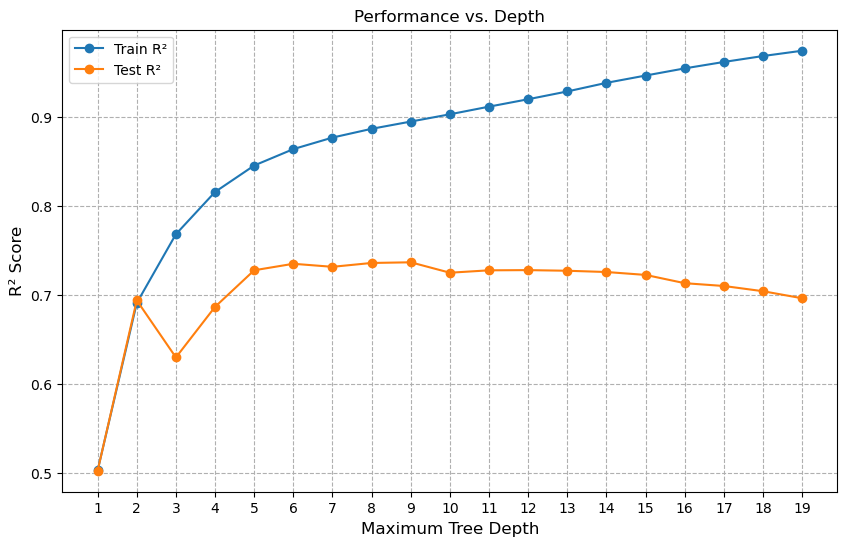

In [97]:
plt.figure(figsize=(10, 6))
plt.plot(depths, train_r2_scores, marker="o", label="Train R²")
plt.plot(depths, test_r2_scores, marker="o", label="Test R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

In [100]:
# Outlier removal for both input features and target variable

model = DecisionTreeRegressor(max_depth=9, random_state=42)
model.fit(x_train_outliers, y_train_outliers)

y_pred = model.predict(x_test_outliers)

score = r2_score(y_test_outliers, y_pred)
score

0.7374048755474243

In [101]:
# Outlier removal for only target variable

model = DecisionTreeRegressor(max_depth=9, random_state=42)
model.fit(x_train_no_scale, y_train_outliers)

y_pred = model.predict(x_test_no_scale)

score = r2_score(y_test_outliers, y_pred)
score

0.7368204279111255

Removing outliers on the target variable has a significant increase on model performance. However, the best result is still a log transform on all large numerical features + a log on the target variable.

### Model Four: Outlier Winsorization on all Features

In [116]:
# Test to see if removing outliers on logged features (via winsorization) improves performance

x_train_mod_4 = x_train_enc.copy()
x_test_mod_4 = x_test_enc.copy()

# Train dataset
upper_bound = x_train_mod_4["LivingAreaLog"].quantile(0.95)
x_train_mod_4["LivingAreaLog"] = x_train_mod_4["LivingAreaLog"].clip(lower=0, upper=upper_bound)

upper_bound = x_train_mod_4["LotSizeSquareFeetLog"].quantile(0.95)
x_train_mod_4["LotSizeSquareFeetLog"] = x_train_mod_4["LotSizeSquareFeetLog"].clip(lower=0, upper=upper_bound)

upper_bound = x_train_mod_4["AssociationFeeLog"].quantile(0.95)
x_train_mod_4["AssociationFeeLog"] = x_train_mod_4["AssociationFeeLog"].clip(lower=0, upper=upper_bound)

# Test dataset
upper_bound = x_test_mod_4["LivingAreaLog"].quantile(0.95)
x_test_mod_4["LivingAreaLog"] = x_test_mod_4["LivingAreaLog"].clip(lower=0, upper=upper_bound)

upper_bound = x_test_mod_4["LotSizeSquareFeetLog"].quantile(0.95)
x_test_mod_4["LotSizeSquareFeetLog"] = x_test_mod_4["LotSizeSquareFeetLog"].clip(lower=0, upper=upper_bound)

upper_bound = x_test_mod_4["AssociationFeeLog"].quantile(0.95)
x_test_mod_4["AssociationFeeLog"] = x_test_mod_4["AssociationFeeLog"].clip(lower=0, upper=upper_bound)

In [117]:
upper_bound_train = train_set["ClosePriceLog"].quantile(0.95)
upper_bound_test = test_set["ClosePriceLog"].quantile(0.95)

y_train_outliers = train_set["ClosePriceLog"].clip(lower=0, upper=upper_bound_train)
y_test_outliers = test_set["ClosePriceLog"].clip(lower=0, upper=upper_bound_test)

In [118]:
depths = range(1, 20)
train_r2_scores = []
test_r2_scores = []

for depth in depths:
    model = DecisionTreeRegressor(max_depth=depth, random_state=42)
    model.fit(x_train_mod_4, y_train_outliers)

    train_r2 = model.score(x_train_mod_4, y_train_outliers)
    test_r2 = model.score(x_test_mod_4, y_test_outliers)

    train_r2_scores.append(train_r2)
    test_r2_scores.append(test_r2)

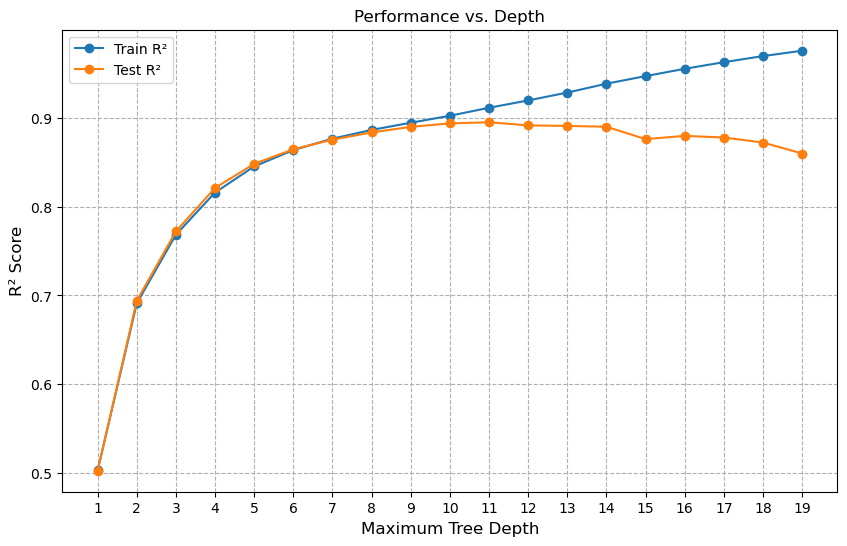

In [119]:
plt.figure(figsize=(10, 6))
plt.plot(depths, train_r2_scores, marker="o", label="Train R²")
plt.plot(depths, test_r2_scores, marker="o", label="Test R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

In [120]:
# Outlier removal on logged input features and target variable

model = DecisionTreeRegressor(max_depth=10, random_state=42)
model.fit(x_train_mod_4, y_train_outliers)

y_pred = model.predict(x_test_mod_4)

score = r2_score(y_test_outliers, y_pred)
score

0.8939375046900301

By keeping the same dataset as the Linear Regression model and applying winsorization on all logged features, we get the best model performance so far.

### Model Five: Outlier Winsorization on Only Target Variable

In [121]:
depths = range(1, 20)
train_r2_scores = []
test_r2_scores = []

for depth in depths:
    model = DecisionTreeRegressor(max_depth=depth, random_state=42)
    model.fit(x_train_enc, y_train_outliers)

    train_r2 = model.score(x_train_enc, y_train_outliers)
    test_r2 = model.score(x_test_enc, y_test_outliers)

    train_r2_scores.append(train_r2)
    test_r2_scores.append(test_r2)

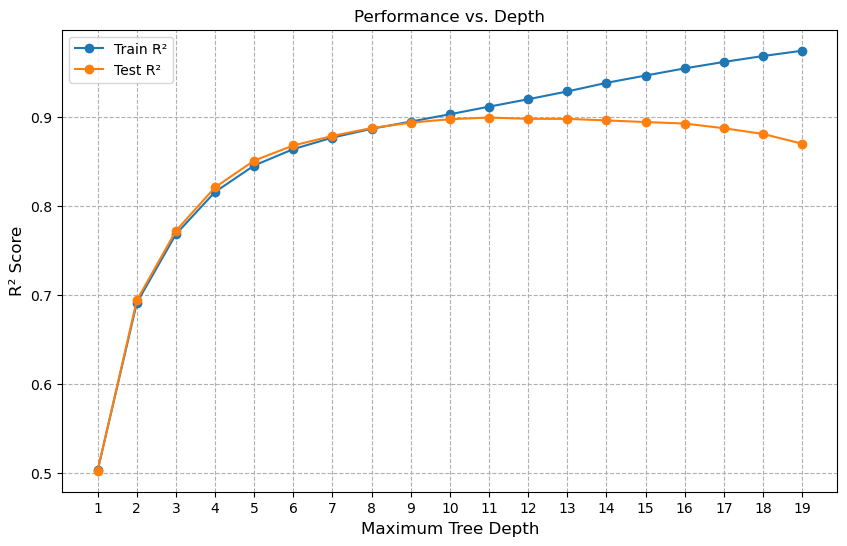

In [122]:
plt.figure(figsize=(10, 6))
plt.plot(depths, train_r2_scores, marker="o", label="Train R²")
plt.plot(depths, test_r2_scores, marker="o", label="Test R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

In [115]:
# Outlier removal on only target variable

model = DecisionTreeRegressor(max_depth=11, random_state=42)
model.fit(x_train_enc, y_train_outliers)

y_pred = model.predict(x_test_enc)

score = r2_score(y_test_outliers, y_pred)
score

0.8996522000050323

There is a very small improvement in model performance by only performing winsorization on the target variable. This is the highest $r^2$ score for the decision trees that I've tried. Overall, the best decision tree performs only slightly better than the best performing Linear Regression model (which had an $r^2$ score of 0.88802).

### Model Six: Dropping Outliers Fully

In [129]:
# Instead of winsorization, see how dropping outliers fully affects model performance

cutoff_train = train_set["ClosePriceLog"].quantile(0.95)
cutoff_test = test_set["ClosePriceLog"].quantile(0.95)

train_set_cut = train_set[train_set["ClosePriceLog"] < cutoff_train]
test_set_cut = test_set[test_set["ClosePriceLog"] < cutoff_test]

y_train_cut = train_set_cut["ClosePriceLog"]
y_test_cut = test_set_cut["ClosePriceLog"]

In [130]:
# Re-do encoding with new outlier-dropped rows

to_encode_train = train_set_cut[["ListOfficeName", "CountyOrParish", "HighSchoolDistrict", "imputed_city", "PostalCode", "imputed_year_built"]]
to_encode_test = test_set_cut[["ListOfficeName", "CountyOrParish", "HighSchoolDistrict", "imputed_city", "PostalCode", "imputed_year_built"]]

y_train = train_set_cut["ClosePriceLog"]
y_test = test_set_cut["ClosePriceLog"]

encoder = TargetEncoder(smooth="auto", cv=5, random_state=42)

x_train_encoded = encoder.fit_transform(to_encode_train, y_train)
x_test_encoded = encoder.transform(to_encode_test)

x_train_encoded_df = pd.DataFrame(x_train_encoded, columns=to_encode_train.columns)
x_test_encoded_df = pd.DataFrame(x_test_encoded, columns=to_encode_train.columns)

x_train = train_set_cut[["ViewYN", "PoolPrivateYN", "AttachedGarageYN", "FireplaceYN", "NewConstructionYN",
                    "LivingAreaLog", "LotSizeSquareFeetLog", "AssociationFeeLog",
                    "ParkingTotalWinz", 'BathroomsTotalIntegerWinz', 'BedroomsTotalWinz', 'MainLevelBedroomsWinz','GarageSpacesWinz', 'ImputedStoriesWinz',
                    'Bamboo', 'Brick', 'Carpet', 'Concrete', 'Laminate', 'Stone', 'Tile', 'Unknown', 'Vinyl', 'Wood',
                    'StateOrProvince_AZ','StateOrProvince_CA', 'StateOrProvince_CO', 'StateOrProvince_FL', 'StateOrProvince_GA',
                    'StateOrProvince_ME', 'StateOrProvince_NV','StateOrProvince_NY', 'StateOrProvince_OS', 'StateOrProvince_TN', 'StateOrProvince_TX']]
x_train_cut = x_train.join(x_train_encoded_df)

x_test = test_set_cut[["ViewYN", "PoolPrivateYN", "AttachedGarageYN", "FireplaceYN", "NewConstructionYN",
                    "LivingAreaLog", "LotSizeSquareFeetLog", "AssociationFeeLog",
                    "ParkingTotalWinz", 'BathroomsTotalIntegerWinz', 'BedroomsTotalWinz', 'MainLevelBedroomsWinz','GarageSpacesWinz', 'ImputedStoriesWinz',
                    'Bamboo', 'Brick', 'Carpet', 'Concrete', 'Laminate', 'Stone', 'Tile', 'Unknown', 'Vinyl', 'Wood',
                    'StateOrProvince_AZ','StateOrProvince_CA', 'StateOrProvince_CO', 'StateOrProvince_FL', 'StateOrProvince_GA',
                    'StateOrProvince_ME', 'StateOrProvince_NV','StateOrProvince_NY', 'StateOrProvince_OS', 'StateOrProvince_TN', 'StateOrProvince_TX']].reset_index(drop=True)
x_test_cut = x_test.join(x_test_encoded_df)

In [131]:
depths = range(1, 20)
train_r2_scores = []
test_r2_scores = []

for depth in depths:
    model = DecisionTreeRegressor(max_depth=depth, random_state=42)
    model.fit(x_train_cut, y_train_cut)

    train_r2 = model.score(x_train_cut, y_train_cut)
    test_r2 = model.score(x_test_cut, y_test_cut)

    train_r2_scores.append(train_r2)
    test_r2_scores.append(test_r2)

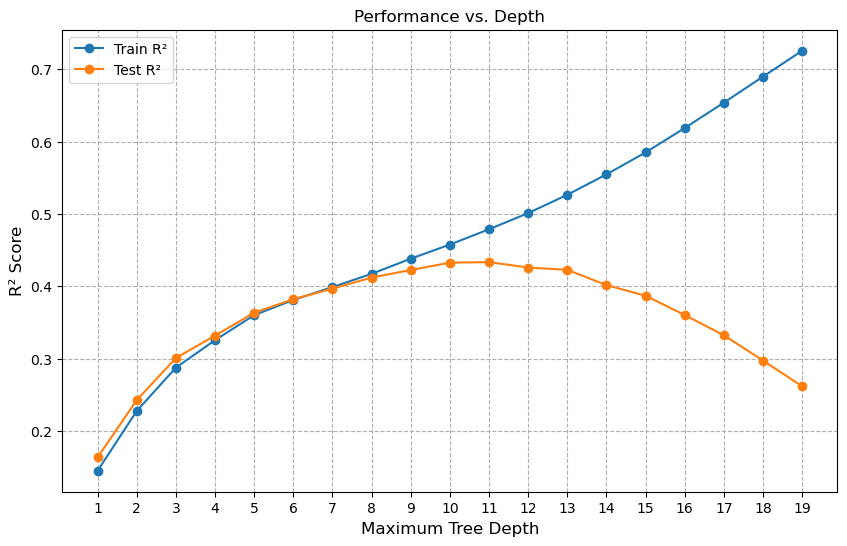

In [132]:
plt.figure(figsize=(10, 6))
plt.plot(depths, train_r2_scores, marker="o", label="Train R²")
plt.plot(depths, test_r2_scores, marker="o", label="Test R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

In [133]:
# Full outlier dropping on only target variable

model = DecisionTreeRegressor(max_depth=11, random_state=42)
model.fit(x_train_cut, y_train_cut)

y_pred = model.predict(x_test_cut)

score = r2_score(y_test_cut, y_pred)
score

0.4334905167494246

Outlier winsorization is far superior to dropping outliers!

### Decision Tree Summary

| Method | $R^2$ Score | Optimal Depth |
| -------| ------------| ------ |
| Baseline Dataset | 0.8731 | 10
| Remove Log from Input Features | 0.69401 | 9
| Remove Log from Input Features + Outlier Removal on all Features | 0.7374 | 9
| Remove Log From Input Features + Outlier Removal on only Target | 0.7368 | 10
| Outlier Winsorization on all Features | 0.8939 | 10
| Outlier Winsorization only on Target | **0.8997** | 11
| Outlier Dropping | 0.4335 | 11

## Random Forest

In [79]:
train_set = dataset[dataset["TestSetTrue"] == 0]
test_set = dataset[dataset["TestSetTrue"] == 1]

to_encode_train = train_set[["ListOfficeName", "CountyOrParish", "HighSchoolDistrict", "imputed_city", "PostalCode", "imputed_year_built"]]
to_encode_test = test_set[["ListOfficeName", "CountyOrParish", "HighSchoolDistrict", "imputed_city", "PostalCode", "imputed_year_built"]]

y_train = train_set["ClosePriceLog"]
y_test = test_set["ClosePriceLog"]

In [80]:
encoder = TargetEncoder(smooth="auto", cv=5, random_state=42)

x_train_encoded = encoder.fit_transform(to_encode_train, y_train)
x_test_encoded = encoder.transform(to_encode_test)

x_train_encoded_df = pd.DataFrame(x_train_encoded, columns=to_encode_train.columns)
x_test_encoded_df = pd.DataFrame(x_test_encoded, columns=to_encode_train.columns)

In [81]:
x_train = train_set[["ViewYN", "PoolPrivateYN", "AttachedGarageYN", "FireplaceYN", "NewConstructionYN",
                    "LivingAreaLog", "LotSizeSquareFeetLog", "AssociationFeeLog",
                    "ParkingTotalWinz", 'BathroomsTotalIntegerWinz', 'BedroomsTotalWinz', 'MainLevelBedroomsWinz','GarageSpacesWinz', 'ImputedStoriesWinz',
                    'Bamboo', 'Brick', 'Carpet', 'Concrete', 'Laminate', 'Stone', 'Tile', 'Unknown', 'Vinyl', 'Wood',
                    'StateOrProvince_AZ','StateOrProvince_CA', 'StateOrProvince_CO', 'StateOrProvince_FL', 'StateOrProvince_GA',
                    'StateOrProvince_ME', 'StateOrProvince_NV','StateOrProvince_NY', 'StateOrProvince_OS', 'StateOrProvince_TN', 'StateOrProvince_TX']]
x_train_enc = x_train.join(x_train_encoded_df)

x_test = test_set[["ViewYN", "PoolPrivateYN", "AttachedGarageYN", "FireplaceYN", "NewConstructionYN",
                    "LivingAreaLog", "LotSizeSquareFeetLog", "AssociationFeeLog",
                    "ParkingTotalWinz", 'BathroomsTotalIntegerWinz', 'BedroomsTotalWinz', 'MainLevelBedroomsWinz','GarageSpacesWinz', 'ImputedStoriesWinz',
                    'Bamboo', 'Brick', 'Carpet', 'Concrete', 'Laminate', 'Stone', 'Tile', 'Unknown', 'Vinyl', 'Wood',
                    'StateOrProvince_AZ','StateOrProvince_CA', 'StateOrProvince_CO', 'StateOrProvince_FL', 'StateOrProvince_GA',
                    'StateOrProvince_ME', 'StateOrProvince_NV','StateOrProvince_NY', 'StateOrProvince_OS', 'StateOrProvince_TN', 'StateOrProvince_TX']].reset_index(drop=True)
x_test_enc = x_test.join(x_test_encoded_df)

### Model One: Baseline Dataset

In [139]:
depths = range(1, 20)
train_r2_scores = []
test_r2_scores = []

for depth in depths:
    model = RandomForestRegressor(n_estimators=100, max_depth=depth, random_state=42, n_jobs=-1)
    model.fit(x_train_enc, y_train)

    train_r2 = model.score(x_train_enc, y_train)
    test_r2 = model.score(x_test_enc, y_test)

    train_r2_scores.append(train_r2)
    test_r2_scores.append(test_r2)

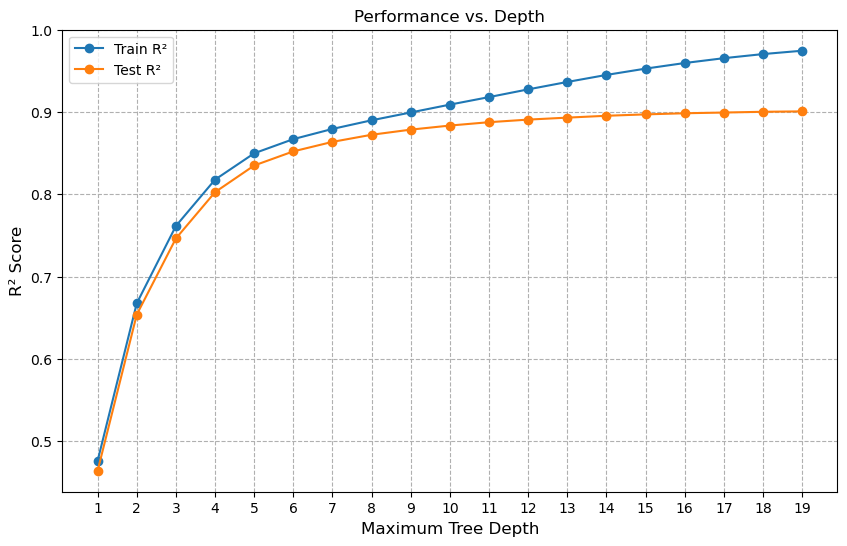

In [140]:
plt.figure(figsize=(10, 6))
plt.plot(depths, train_r2_scores, marker="o", label="Train R²")
plt.plot(depths, test_r2_scores, marker="o", label="Test R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

In [7]:
model = RandomForestRegressor(n_estimators=100, max_depth=16, random_state=42, n_jobs=-1)
model.fit(x_train_enc, y_train)

y_pred = model.predict(x_test_enc)

score = r2_score(y_test, y_pred)
score

0.8985831651539412

As expected, a random forest performs better than a decision tree for the same data (the decision tree got 0.87314). However, this is not a very drastic improvement.

### Model Two: Outlier Winsorization on Target Variable

In [82]:
# The best performing dataset for the decision tree was the outlier winsorization applied only to the target variable.
# Let's see how a random forest performs on this same data

upper_bound_train = train_set["ClosePriceLog"].quantile(0.95)
upper_bound_test = test_set["ClosePriceLog"].quantile(0.95)

y_train_outliers = train_set["ClosePriceLog"].clip(lower=0, upper=upper_bound_train)
y_test_outliers = test_set["ClosePriceLog"].clip(lower=0, upper=upper_bound_test)

In [10]:
depths = range(1, 20)
train_r2_scores = []
test_r2_scores = []

for depth in depths:
    model = RandomForestRegressor(n_estimators=100, max_depth=depth, random_state=42, n_jobs=-1)
    model.fit(x_train_enc, y_train_outliers)

    train_r2 = model.score(x_train_enc, y_train_outliers)
    test_r2 = model.score(x_test_enc, y_test_outliers)

    train_r2_scores.append(train_r2)
    test_r2_scores.append(test_r2)

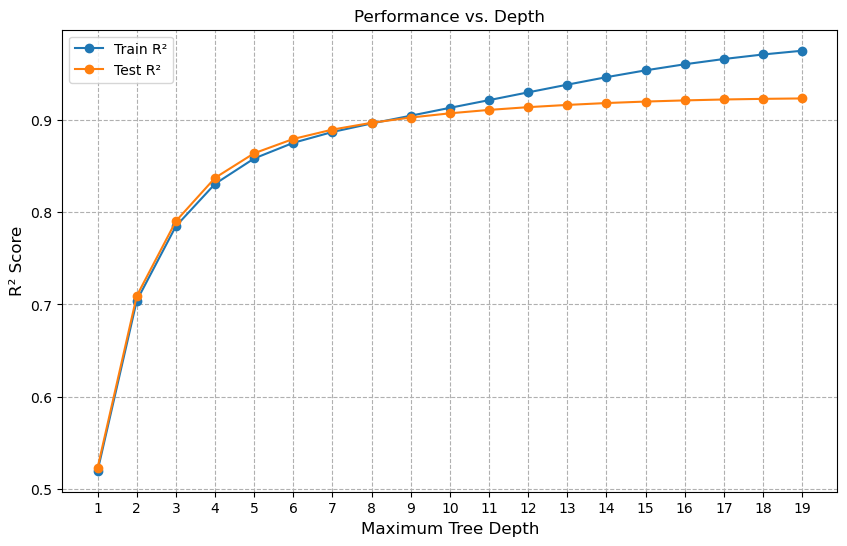

In [11]:
plt.figure(figsize=(10, 6))
plt.plot(depths, train_r2_scores, marker="o", label="Train R²")
plt.plot(depths, test_r2_scores, marker="o", label="Test R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

In [52]:
model = RandomForestRegressor(n_estimators=100, max_depth=17, random_state=42, n_jobs=-1)
model.fit(x_train_enc, y_train_outliers)

y_pred = model.predict(x_test_enc)

score = r2_score(y_test_outliers, y_pred)
score

0.9224509623233523

Removing the outliers on the target variable leads to a decent jump in model performance, as expected.

### Model Three: Tuning `max_features`

In [76]:
# The previous model worked very well. It is a good idea now to tune that one further
# Above model used max_features = 1.0 (all features). Try different options for max_features.
# Here: max_features = "sqrt"

model = RandomForestRegressor(n_estimators=100, max_depth=17, random_state=42, n_jobs=-1, max_features = "sqrt")
model.fit(x_train_enc, y_train_outliers)

y_pred = model.predict(x_test_enc)

score = r2_score(y_test_outliers, y_pred)
score

0.9168293698146688

In [72]:
# max_features = "log2"

model = RandomForestRegressor(n_estimators=100, max_depth=17, random_state=42, n_jobs=-1, max_features = "log2")
model.fit(x_train_enc, y_train_outliers)

y_pred = model.predict(x_test_enc)

score = r2_score(y_test_outliers, y_pred)
score

0.9144328290217509

The default max_features = 0.1 (all features) still gives the best performance.

### Model Four: Tuning `min_samples_split`

In [85]:
splits = range(2, 11)
train_r2_scores = []
test_r2_scores = []

for split in splits:
    model = RandomForestRegressor(n_estimators=100, max_depth=17, random_state=42, n_jobs=-1, min_samples_split=split)
    model.fit(x_train_enc, y_train_outliers)

    train_r2 = model.score(x_train_enc, y_train_outliers)
    test_r2 = model.score(x_test_enc, y_test_outliers)

    train_r2_scores.append(train_r2)
    test_r2_scores.append(test_r2)

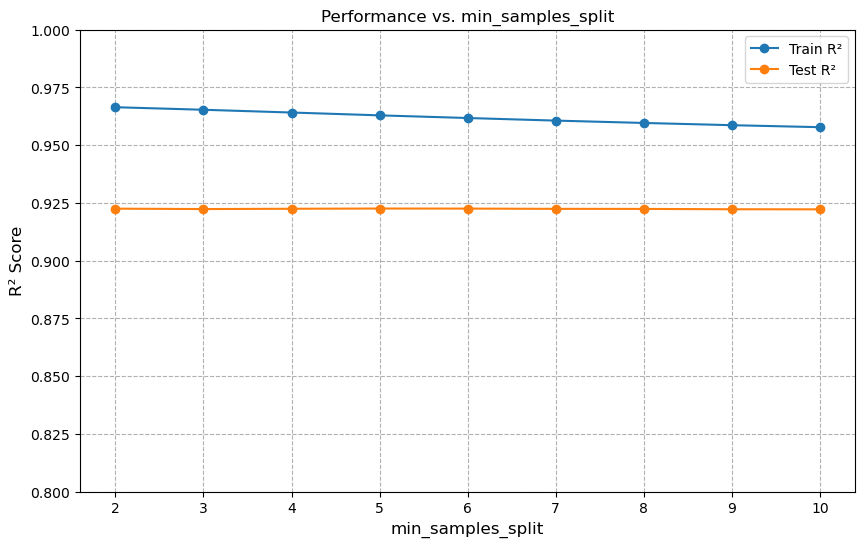

In [90]:
plt.figure(figsize=(10, 6))
plt.plot(splits, train_r2_scores, marker="o", label="Train R²")
plt.plot(splits, test_r2_scores, marker="o", label="Test R²")

plt.xlabel("min_samples_split", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. min_samples_split")
plt.xticks(splits)
plt.ylim(0.8, 1) 
plt.grid(True, linestyle="--")
plt.legend()

In [93]:
model = RandomForestRegressor(n_estimators=100, max_depth=17, random_state=42, n_jobs=-1, min_samples_split=2)
model.fit(x_train_enc, y_train_outliers)

y_pred = model.predict(x_test_enc)

score = r2_score(y_test_outliers, y_pred)
score

0.9224509623233522

Again, the default value (2) performs the best.

### Model Five: Tuning `min_samples_leaf`

In [94]:
leaves = range(1, 11)
train_r2_scores = []
test_r2_scores = []

for leaf in leaves:
    model = RandomForestRegressor(n_estimators=100, max_depth=17, random_state=42, n_jobs=-1, min_samples_leaf = leaf)
    model.fit(x_train_enc, y_train_outliers)

    train_r2 = model.score(x_train_enc, y_train_outliers)
    test_r2 = model.score(x_test_enc, y_test_outliers)

    train_r2_scores.append(train_r2)
    test_r2_scores.append(test_r2)

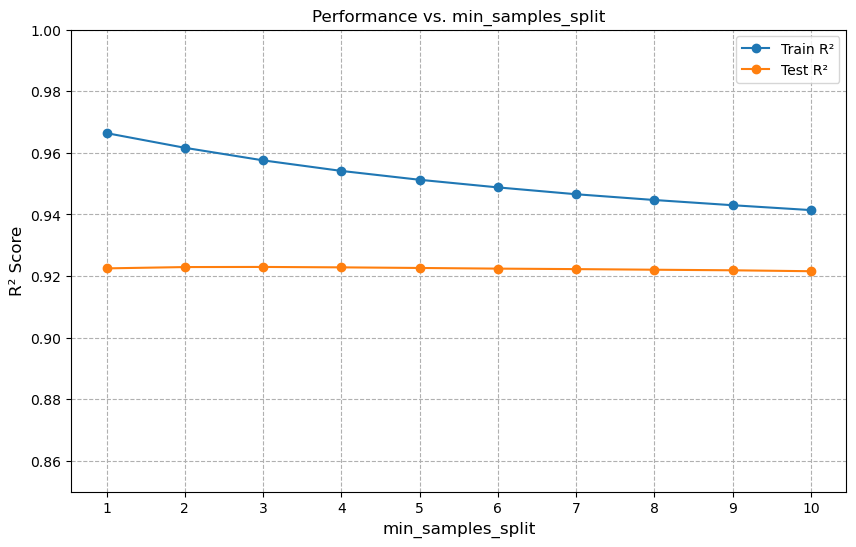

In [97]:
plt.figure(figsize=(10, 6))
plt.plot(leaves, train_r2_scores, marker="o", label="Train R²")
plt.plot(leaves, test_r2_scores, marker="o", label="Test R²")

plt.xlabel("min_samples_split", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. min_samples_split")
plt.xticks(leaves)
plt.ylim(0.85, 1) 
plt.grid(True, linestyle="--")
plt.legend()

In [99]:
model = RandomForestRegressor(n_estimators=100, max_depth=17, random_state=42, n_jobs=-1, min_samples_leaf=3)
model.fit(x_train_enc, y_train_outliers)

y_pred = model.predict(x_test_enc)

score = r2_score(y_test_outliers, y_pred)
score

0.9229139824024924

The model performs very very slightly better when min_samples_leaf is set to 3 instead of 1. However, this is too small of a change to really say that parameter tuning has been successful. Continuing with the default value seems to be the best path.

### Random Forest Summary

| Method | $R^2$ Score | Depth |
| -------| ------------| ----- |
| Baseline Dataset | 0.8986 | 16
| Outlier Winsorization only on Target | 0.9225 | 17
| Tuning max_features | 0.9168 | 17
| Tuning min_samples_split | 0.9225 | 17
| Tuning min_samples_leaf | **0.9229** | 17